2.0
1.5
1.3333333333333333
1.3333333333333333
1.3333333333333333
[(1, 0), (3, 0), (4, 0)]


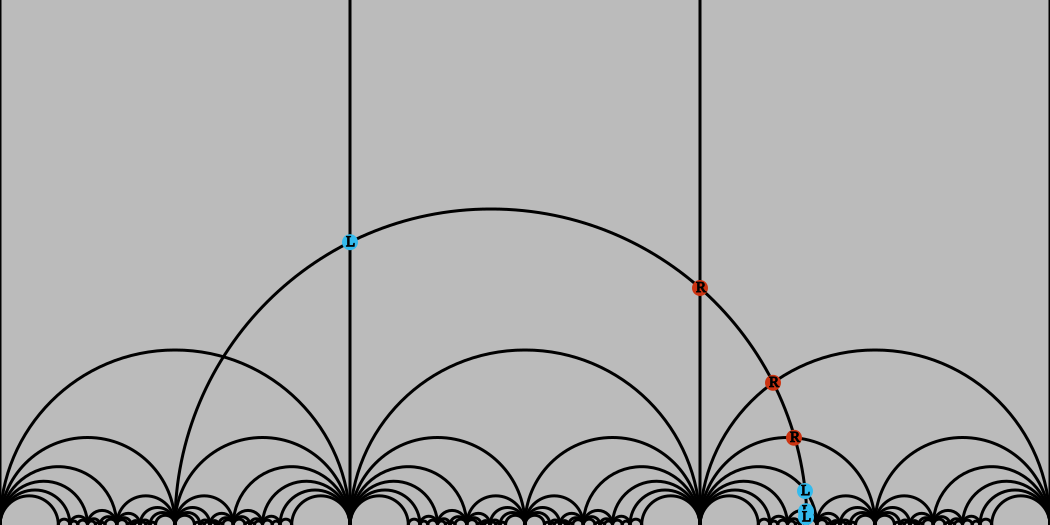

In [7]:
import drawsvg as draw
import math

def gen_scf(n):

    seq = [] #Initialize sequence

    if n[0] < n[1]: #if n < 1, a_0 = 0
        seq.append((0,0))

        num = n[0]
        den = n[1]
    else: #Take reciprocal
        num = n[1]
        den = n[0]
    while num != 1:

        tmp = num
        num = den
        den = tmp

        if den == 0:
            break

        a = math.floor(num / den) #get a_i term
        seq.append((a,0)) #add to list
        num = num - (a * den) #move down sequence
    seq.append((den,0))
    print(seq)
    return seq

def gen_farey(n):
    seq = [(0,1),(1,1)] #Seed initial sequence
    iterations = [seq] 
    for i in range(0, n):
        new_seq = []
        for j in range(0, len(seq)-1):
            new_seq.append(seq[j])
            new_seq.append((seq[j][0]+seq[j+1][0], seq[j][1]+seq[j+1][1]))
        new_seq.append(seq[-1])
        iterations.append(new_seq)
        seq = new_seq
    return(iterations)

def draw_farey(farey_level, interval_size, d, length, width, canvas_size):
    coordinate = 0
    for i in range(0,11):
        d.append(draw.Line(coordinate,0,coordinate,width, stroke='black', stroke_width=3))
        coordinate += interval_size
    iterations = gen_farey(farey_level)
    for i in range(0, 11):
        offset = i*interval_size
        for it in iterations:
            for i in range(0, len(it)-1):
                r = (interval_size*it[i+1][0]/it[i+1][1] - interval_size*it[i][0]/it[i][1])/2
                x1 = interval_size * it[i][0]/it[i][1]
                x2 = interval_size * it[i+1][0]/it[i+1][1]
                centerpoint = (x2-x1)/2 
                d.append(draw.Circle(offset+centerpoint+x1,canvas_size/2, r, stroke='black', fill='none', stroke_width=3))

def fracToPixel(frac, interval_size):
    return interval_size + (frac[0]*interval_size // frac[1])

def drawGeodesic(p1, p2, d, width):
    d.append(draw.Circle(((p1+p2)//2),width, ((p2 - p1) //2), fill='none', stroke='black', stroke_width=3))

def getIntersection(g1,g2,h1,h2, width):
    r1 = (g2-g1)/2
    r2 = (h2-h1)/2
    m1 = (g1+g2)/2
    m2 = (h1+h2)/2

    x = ((r1**2) - (r2**2) - (m1**2) + (m2**2)) // (2 * (m2 - m1))
    y = math.sqrt((r2**2) - ((x-m2)**2))
    return (x,width-y)

def getGeodesicIntersections(g1,g2,fn, interval_size, width):
    intersection_points = []

    g1p = fracToPixel(g1, interval_size)
    g2p = fracToPixel(g2, interval_size)

    m = (g1p+g2p)/2
    r = (g2p-g1p)/2

    eta = math.floor(g2[0]/g2[1])

    for x in range(0, eta+1):
        x = fracToPixel([x,1], interval_size)
        intersection_points.append((x, width - math.sqrt((r**2) - ((x-m)**2))))

    g = g2[0]/g2[1]
    fareys = gen_farey(fn)

    for farey in fareys:
        for k in range(0, len(farey)):
            p = eta + (farey[k][0]/farey[k][1])
            if g < p:

                h1 = fracToPixel((farey[k-1][0]+(eta*farey[k-1][1]), farey[k-1][1]), interval_size)
                h2 = fracToPixel((farey[k][0]+(eta*farey[k][1]), farey[k][1]), interval_size)
                v1 = fracToPixel(g1, interval_size)
                v2 = fracToPixel(g2, interval_size)

                intersection_points.append(getIntersection(v1,v2,h1,h2,width))
                print(p)
                break
    return intersection_points

def drawGeodesicIntersections(d, intersections, p2):
    seq = gen_scf(p2)
    count = 0
    lr = 0
    for i in range(0, len(intersections)):
        if len(seq) == 0:
            break
        if lr % 2 == 0:
            d.append(draw.Circle(intersections[i][0], intersections[i][1], 8, fill='#33BBEE'))
            d.append(draw.Text("L", font_size=15, x=intersections[i][0]-4, y=intersections[i][1]+4, stroke='black'))
        else:
            d.append(draw.Circle(intersections[i][0], intersections[i][1], 8, fill='#CC3311'))
            d.append(draw.Text("R", font_size=15, x=intersections[i][0]-4, y=intersections[i][1]+4, stroke='black'))
        count += 1
        if count == seq[0][0]:
            lr += 1
            count = 0
            seq.pop(0)


interval_size=350 #pixel size of each interval (n, n+1)
length = interval_size*3 #total size of canvas = size of interval * # of intervals
width = (interval_size*3)//2 #Half the size of length
canvas_size = interval_size*3 #i don remembr

gamma_negative = [-1,2]
gamma_positive = [17,13]

gamma_negative_pixel = fracToPixel(gamma_negative, interval_size)
gamma_positive_pixel = fracToPixel(gamma_positive, interval_size)

d = draw.Drawing(length, width, origin=(0,0)) #Create new canvas 
d.append(draw.Rectangle(0,0, length, width, fill='#BBBBBB'))
draw_farey(5, interval_size, d, length, width, canvas_size) #Draw farey to depth n
drawGeodesic(gamma_negative_pixel, gamma_positive_pixel, d, width) #Draw geodesic from endpoint to endpoint

intersections = getGeodesicIntersections(gamma_negative, gamma_positive, 4, interval_size, width) #create list of intersections of geo with farey
drawGeodesicIntersections(d, intersections, gamma_positive) #draw intersections

d


